
## Step 1: Connect and Review the CICIoT2023 Data

The CICIoT2023 network traffic file is loaded from the GitHub Codespaces project folder. The data is reviewed to confirm the number of records, available fields, and network attack categories before the Machine Learning analysis begins.

The public dataset is evaluated separately from the simulated RFID baggage tracking records. The original H2 results remain unchanged.


In [1]:

# Step 1: Connect and review the CICIoT2023 data


# Load the libraries

import os
import pandas as pd


# Set the main project folder

main_folder = os.getcwd()

if not os.path.isdir(main_folder + "/02_CICIoT2023"):
    main_folder = os.path.dirname(main_folder)


# Set the CICIoT2023 data folder

cic_folder = main_folder + "/02_CICIoT2023/data"


# Set the network traffic file

cic_file = (
    cic_folder +
    "/Merged32.csv"
)


# Load the CICIoT2023 data

cic_data = pd.read_csv(cic_file)

print("The CICIoT2023 data is connected.")


# Check the dataset size

print(
    "\nTotal network traffic records:",
    len(cic_data)
)

print(
    "Total columns:",
    len(cic_data.columns)
)


# Check the available fields

print("\nCICIoT2023 fields:")

print(
    cic_data.columns.tolist()
)


# Identify the network traffic labels

print("\nNetwork traffic categories:")

if "label" in cic_data.columns:

    print(
        cic_data["label"].value_counts()
    )

elif "Label" in cic_data.columns:

    print(
        cic_data["Label"].value_counts()
    )

else:

    print("The label column needs to be identified.")


The CICIoT2023 data is connected.

Total network traffic records: 704067
Total columns: 40

CICIoT2023 fields:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label']

Network traffic categories:
Label
DDOS-ICMP_FLOOD            107281
DDOS-UDP_FLOOD              80363
DDOS-TCP_FLOOD              67250
DDOS-PSHACK_FLOOD           61262
DDOS-RSTFINFLOOD            60934
DDOS-SYN_FLOOD              60586
DDOS-SYNONYMOUSIP_FLOOD     53809
DOS-UDP_FLOOD               50203
DOS-TCP_FLOOD               40598
DOS-SYN_FLOOD               30409
BENIGN                      16507
MIRAI-GREETH_FLOOD          1475


## Step 2: Prepare the Network Attack Labels

The CICIoT2023 dataset contains normal network traffic and several categories of malicious activity. The original attack labels are reviewed and prepared for the Machine Learning comparison.

A separate working copy of the dataset is created so the original network traffic records remain unchanged. Normal traffic, identified as BENIGN, is assigned a value of 0. Records identified as network attacks are assigned a value of 1.

This creates a binary classification target that allows Logistic Regression, Support Vector Machine, and Random Forest to distinguish normal traffic from malicious activity.

The original attack categories are preserved in the working data for reference. The number of normal and attack records is also reviewed because differences between these groups can affect how Machine Learning performance is interpreted.


In [2]:

# Step 2: Prepare the network attack labels


# Create a separate working copy

cic_model_data = cic_data.copy()


# Standardize the original attack labels

cic_model_data["Label"] = (
    cic_model_data["Label"]
    .astype("string")
    .str.strip()
    .str.upper()
)


# Remove records with missing or empty labels

cic_model_data = cic_model_data.dropna(
    subset=["Label"]
)

cic_model_data = cic_model_data.loc[
    cic_model_data["Label"] != ""
].copy()


# Create the binary attack label
# 0 = Normal network traffic
# 1 = Malicious network traffic

cic_model_data["attack_label"] = (
    cic_model_data["Label"] != "BENIGN"
).astype(int)


# Review the prepared records

print(
    "Total prepared records:",
    len(cic_model_data)
)


# Count normal network traffic

print(
    "\nNormal traffic records:",
    (cic_model_data["attack_label"] == 0).sum()
)


# Count malicious network traffic

print(
    "Attack traffic records:",
    (cic_model_data["attack_label"] == 1).sum()
)


# Review the binary label distribution

print("\nMachine Learning target distribution:")

print(
    cic_model_data["attack_label"].value_counts().sort_index()
)


# Calculate the percentage of each traffic class

print("\nTraffic distribution percentages:")

print(
    (
        cic_model_data["attack_label"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


# Confirm the original attack categories remain available

print(
    "\nOriginal network traffic categories:",
    cic_model_data["Label"].nunique()
)


Total prepared records: 704067

Normal traffic records: 16507
Attack traffic records: 687560

Machine Learning target distribution:
attack_label
0     16507
1    687560
Name: count, dtype: int64

Traffic distribution percentages:
attack_label
0     2.34
1    97.66
Name: proportion, dtype: float64

Original network traffic categories: 34



## Step 3: Prepare the Features and Training Data

The CICIoT2023 records are prepared for the Machine Learning comparison by separating the network traffic features from the attack labels. The features contain the information the models will examine, while the attack label identifies whether each record represents normal or malicious activity.

The dataset is divided into 70% training data and 30% testing data. The training records will be used to develop the models, while the testing records will be reserved for evaluating their performance.

A stratified split is used to maintain the original proportion of normal and malicious traffic in both groups. This is necessary because the dataset contains substantially more attack records than normal records.

The split is performed at the individual record level. The resulting evaluation will therefore measure performance on held out records rather than establish generalization to entirely independent devices or network sessions.

The original RFID baggage tracking experiment remains unchanged.


In [3]:

# Step 3: Prepare the features and training data

# Load the Machine Learning library

from sklearn.model_selection import train_test_split


# Separate the network traffic features
# Do not include the known attack labels

cic_features = cic_model_data.drop(
    columns=["Label", "attack_label"]
)


# Select the numerical network traffic features

cic_features = cic_features.select_dtypes(
    include="number"
)


# Set the target variable
# 0 = Normal traffic
# 1 = Attack traffic

cic_target = cic_model_data["attack_label"]


# Divide the records into training and testing groups
# Use 70% for training and 30% for testing
# Keep the same traffic class proportions

X_train, X_test, y_train, y_test = train_test_split(
    cic_features,
    cic_target,
    test_size=0.30,
    random_state=42,
    stratify=cic_target
)


# Review the selected features

print("Total Machine Learning features:", X_train.shape[1])


# Review the training and testing records

print("\nTraining records:", len(X_train))

print("Testing records:", len(X_test))


# Review the training labels

print("\nTraining label distribution:")

print(y_train.value_counts().sort_index())


# Review the testing labels

print("\nTesting label distribution:")

print(y_test.value_counts().sort_index())


# Review the traffic percentages in the testing data

print("\nTesting traffic percentages:")

print(
    (
        y_test.value_counts(normalize=True).sort_index()
        * 100
    ).round(2)
)


Total Machine Learning features: 39

Training records: 492846
Testing records: 211221

Training label distribution:
attack_label
0     11555
1    481291
Name: count, dtype: int64

Testing label distribution:
attack_label
0      4952
1    206269
Name: count, dtype: int64

Testing traffic percentages:
attack_label
0     2.34
1    97.66
Name: proportion, dtype: float64



## Step 4: Prepare the Network Features for Machine Learning

The network traffic features are prepared before the Machine Learning models are trained. Missing or infinite values are handled to prevent errors during model development.

Missing values are replaced using the median values calculated from the training records. The same training values are applied to the testing records so that the testing data does not influence the preparation process.

The numerical features are also standardized for Logistic Regression and Support Vector Machine. Random Forest will use the cleaned numerical features without standardization.

The original dataset and attack labels remain unchanged.


In [4]:

# Step 4: Prepare the network features

# Load the libraries
import numpy as np
from sklearn.preprocessing import StandardScaler


# Create working copies of the training and testing data
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()


# Replace infinite values with missing values
X_train_clean = X_train_clean.replace([np.inf, -np.inf], np.nan)
X_test_clean = X_test_clean.replace([np.inf, -np.inf], np.nan)


# Calculate the median using training data only
train_medians = X_train_clean.median().fillna(0)


# Fill missing values using the training medians
X_train_clean = X_train_clean.fillna(train_medians)
X_test_clean = X_test_clean.fillna(train_medians)


# Standardize the numerical features
scaler = StandardScaler()

# Learn the scaling values from training data
X_train_scaled = scaler.fit_transform(X_train_clean)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test_clean)


# Display the prepared data sizes
print("Feature preparation is complete.")

print("\nTraining records:", X_train_scaled.shape[0])
print("Testing records:", X_test_scaled.shape[0])
print("Total features:", X_train_scaled.shape[1])

print("\nThe data is ready for Machine Learning.")


Feature preparation is complete.

Training records: 492846
Testing records: 211221
Total features: 39

The data is ready for Machine Learning.



## Step 5: Address the Class Imbalance

The CICIoT2023 training data contains substantially more malicious traffic than normal traffic. This difference may affect how the Machine Learning models identify the two categories.

Class weights are calculated to account for the unequal number of records. Normal traffic receives greater weight because fewer normal records are available. Attack traffic receives a lower weight because it represents most of the dataset.

The weights will be used when training Logistic Regression, Support Vector Machine, and Random Forest. This approach keeps the original training and testing records unchanged while accounting for the difference between the two traffic categories.


In [5]:

# Step 5: Address the class imbalance

# Load the class weight library
from sklearn.utils.class_weight import compute_class_weight


# Identify the two traffic categories
# 0 = Normal traffic
# 1 = Attack traffic

classes = np.array([0, 1])


# Calculate weights using the training labels
# Give more weight to the smaller traffic category

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)


# Store the weights for the three models

class_weights = {
    0: weights[0],
    1: weights[1]
}


# Display the calculated class weights

print("Class weights are ready.")

print(
    "\nNormal traffic weight:",
    round(class_weights[0], 2)
)

print(
    "Attack traffic weight:",
    round(class_weights[1], 2)
)


# Confirm the training data remains unchanged

print(
    "\nTraining records:",
    len(y_train)
)

print(
    "Testing records:",
    len(y_test)
)


Class weights are ready.

Normal traffic weight: 21.33
Attack traffic weight: 0.51

Training records: 492846
Testing records: 211221



## Step 6: Train the Logistic Regression Model

Logistic Regression is the first Machine Learning model evaluated using the CICIoT2023 network traffic data. The model uses the prepared training records to learn differences between normal and malicious activity.

The class weights calculated in Step 5 are applied during training to account for the smaller number of normal traffic records. The standardized features prepared in Step 4 are used for model training and testing.

After training, the model predicts whether each testing record represents normal traffic or an attack. These predictions will be used later to calculate accuracy, precision, recall, F1 score, and the confusion matrix.

The results will be compared with Support Vector Machine and Random Forest using the same testing data.


In [6]:

# Step 6: Train the Logistic Regression model


# Load the Machine Learning model

from sklearn.linear_model import LogisticRegression


# Set up the Logistic Regression model
# Use the class weights from Step 5

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight=class_weights,
    random_state=42
)


# Train the model using the prepared training data

logistic_model.fit(
    X_train_scaled,
    y_train
)


# Predict normal and attack traffic

logistic_predictions = logistic_model.predict(
    X_test_scaled
)


# Confirm training is complete

print("Logistic Regression training complete.")


# Count the testing predictions

print(
    "\nTotal predictions:",
    len(logistic_predictions)
)


# Count predicted normal traffic

print(
    "Predicted normal traffic:",
    (logistic_predictions == 0).sum()
)


# Count predicted attack traffic

print(
    "Predicted attack traffic:",
    (logistic_predictions == 1).sum()
)


Logistic Regression training complete.

Total predictions: 211221
Predicted normal traffic: 9842
Predicted attack traffic: 201379



## Step 7: Train the Support Vector Machine Model

Support Vector Machine is the second Machine Learning method evaluated using CICIoT2023. The model learns to separate normal network traffic from malicious activity using the prepared numerical features.

A linear Support Vector Machine is used because the public dataset contains a substantially larger number of training records than the original RFID experiment. The original H2 experiment used an RBF kernel, so the difference in model configuration must be considered when interpreting results across the two experiments.

The class weights calculated in Step 5 are applied during training. Predictions are generated using the same testing records used for Logistic Regression.

The model results will be evaluated and compared with Logistic Regression and Random Forest.


In [7]:

# Step 7: Train the Support Vector Machine model


# Load the Machine Learning model

from sklearn.svm import LinearSVC


# Set up the Support Vector Machine model
# Use the class weights from Step 5
# Use a linear model for the larger dataset

svm_model = LinearSVC(
    class_weight=class_weights,
    dual=False,
    max_iter=5000
)


# Train the Support Vector Machine model

svm_model.fit(
    X_train_scaled,
    y_train
)


# Predict normal and attack traffic

svm_predictions = svm_model.predict(
    X_test_scaled
)


# Confirm training is complete

print("Support Vector Machine training complete.")


# Count the testing predictions

print(
    "\nTotal predictions:",
    len(svm_predictions)
)


# Count predicted normal traffic

print(
    "Predicted normal traffic:",
    (svm_predictions == 0).sum()
)


# Count predicted attack traffic

print(
    "Predicted attack traffic:",
    (svm_predictions == 1).sum()
)


Support Vector Machine training complete.

Total predictions: 211221
Predicted normal traffic: 9909
Predicted attack traffic: 201312



## Step 8: Train the Random Forest Model

Random Forest is the third Machine Learning model evaluated using CICIoT2023. Unlike Logistic Regression and Support Vector Machine, Random Forest uses multiple decision trees to classify network traffic.

Each decision tree examines the network traffic features and contributes to the final prediction. The model is trained using the same records and class weights applied to the other two models.

The number and depth of the trees are limited to manage computing resources because CICIoT2023 contains considerably more records than the original RFID dataset. These settings differ from the original H2 Random Forest configuration and will be considered when interpreting the supplemental findings.

The model predicts normal and malicious network activity using the same testing records. Its performance will be compared with Logistic Regression and Support Vector Machine during the evaluation.


In [8]:

# Step 8: Train the Random Forest model


# Load the Machine Learning model

from sklearn.ensemble import RandomForestClassifier


# Set up the Random Forest model
# Use 100 decision trees
# Limit tree depth to manage memory
# Use the class weights from Step 5

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=5,
    class_weight=class_weights,
    random_state=42,
    n_jobs=2
)


# Train the Random Forest model

random_forest_model.fit(
    X_train_clean,
    y_train
)


# Predict normal and attack traffic

random_forest_predictions = random_forest_model.predict(
    X_test_clean
)


# Confirm training is complete

print("Random Forest training complete.")


# Count the testing predictions

print(
    "\nTotal predictions:",
    len(random_forest_predictions)
)


# Count predicted normal traffic

print(
    "Predicted normal traffic:",
    (random_forest_predictions == 0).sum()
)


# Count predicted attack traffic

print(
    "Predicted attack traffic:",
    (random_forest_predictions == 1).sum()
)


Random Forest training complete.

Total predictions: 211221
Predicted normal traffic: 8391
Predicted attack traffic: 202830



## Step 9: Evaluate and Compare the Machine Learning Models

The three Machine Learning models are evaluated using the testing records prepared in Step 3. Logistic Regression, Support Vector Machine, and Random Forest are compared using accuracy, precision, recall, F1 score, and confusion matrices.

Accuracy measures the overall percentage of correct predictions. Precision examines how often traffic classified as an attack is actually malicious. Recall measures how many actual attacks are correctly identified. F1 score combines precision and recall into one measurement.

The CICIoT2023 dataset contains considerably more malicious traffic than normal traffic. Balanced accuracy and normal traffic recall are therefore included to examine whether the models perform well across both categories.

The confusion matrices identify correct predictions, false alarms, and missed attacks. These results will be used to determine which model performs best in the supplemental network traffic experiment.

The findings will not be treated as direct evidence of RFID reader spoofing detection because CICIoT2023 contains network traffic rather than baggage scan records.

In [9]:

# Step 9: Evaluate the Machine Learning models

# Load the evaluation libraries

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


# Set up the three models for comparison

models = [
    ("Logistic Regression", logistic_predictions),
    ("Support Vector Machine", svm_predictions),
    ("Random Forest", random_forest_predictions)
]


# Create an empty list for the results

results = []


# Evaluate each model using the same testing labels

for model_name, predictions in models:

    # Calculate the evaluation scores

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    # Measure performance across both traffic categories

    balanced_accuracy = balanced_accuracy_score(
        y_test, predictions
    )

    # Measure how well normal traffic is identified

    normal_recall = recall_score(
        y_test, predictions, pos_label=0, zero_division=0
    )

    # Store the results for comparison

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Balanced Accuracy": balanced_accuracy,
        "Normal Recall": normal_recall
    })

    # Display the confusion matrix
    # Rows = Actual labels
    # Columns = Predicted labels
    # Label 0 = Normal
    # Label 1 = Attack

    print("\nModel:", model_name)

    print("\nConfusion Matrix:")

    print(
        confusion_matrix(
            y_test, predictions, labels=[0, 1]
        )
    )

    # Display results for normal and attack traffic

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Normal", "Attack"],
            zero_division=0
        )
    )


# Create a comparison table

comparison_results = pd.DataFrame(results)


# Display the final model comparison

print("\nFinal Machine Learning Comparison:")

print(
    comparison_results.round(4).to_string(index=False)
)



Model: Logistic Regression

Confusion Matrix:
[[  4952      0]
 [  4890 201379]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.50      1.00      0.67      4952
      Attack       1.00      0.98      0.99    206269

    accuracy                           0.98    211221
   macro avg       0.75      0.99      0.83    211221
weighted avg       0.99      0.98      0.98    211221


Model: Support Vector Machine

Confusion Matrix:
[[  4952      0]
 [  4957 201312]]

Classification Report:
              precision    recall  f1-score   support

      Normal       0.50      1.00      0.67      4952
      Attack       1.00      0.98      0.99    206269

    accuracy                           0.98    211221
   macro avg       0.75      0.99      0.83    211221
weighted avg       0.99      0.98      0.98    211221


Model: Random Forest

Confusion Matrix:
[[  4946      6]
 [  3445 202824]]

Classification Report:
              precision    reca


## Step 10: Save the Machine Learning Results and Figures

The results from Logistic Regression, Support Vector Machine, and Random Forest are saved for the final research analysis.

The model comparison table includes accuracy, precision, recall, F1 score, balanced accuracy, and normal traffic recall. The confusion matrix results are also saved to document correct predictions, false alarms, and missed attacks.

A figure comparing missed attacks is generated to show differences in detection performance. The files are saved separately from the original RFID H2 results to preserve the distinction between the two experiments.

These outputs will support the reporting of the supplemental cybersecurity findings in Chapter 4.


Model comparison table saved.
Confusion matrix table saved.


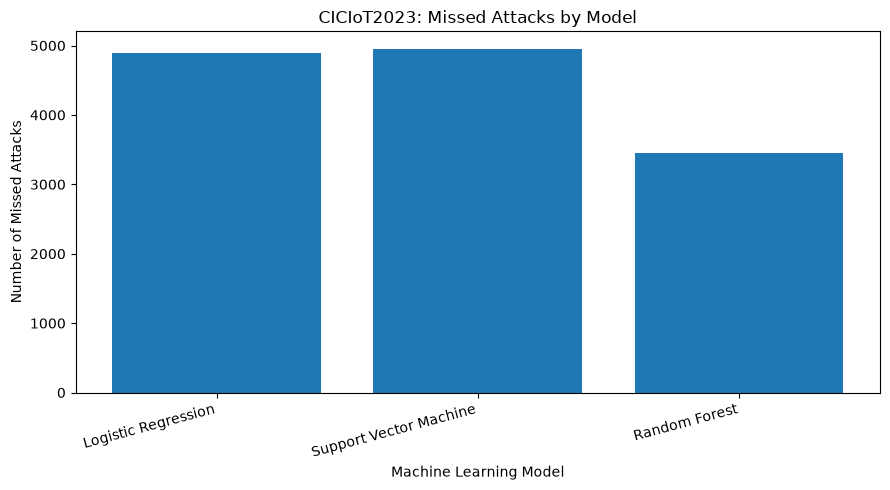


CICIoT2023 results saved successfully.

Model comparison:
                 Model  Accuracy  Precision  Recall  F1 Score  Balanced Accuracy  Normal Recall
   Logistic Regression    0.9768        1.0  0.9763    0.9880             0.9881         1.0000
Support Vector Machine    0.9765        1.0  0.9760    0.9878             0.9880         1.0000
         Random Forest    0.9837        1.0  0.9833    0.9916             0.9910         0.9988

Confusion matrix results:
                 Model  Correct Normal  False Alarms  Missed Attacks  Correct Attacks
   Logistic Regression            4952             0            4890           201379
Support Vector Machine            4952             0            4957           201312
         Random Forest            4946             6            3445           202824


In [10]:

# Step 10: Save the CICIoT2023 results


# Load the plotting library

import matplotlib.pyplot as plt


# Set the H2 results folder

results_folder = main_folder + "/08_H2_Results"

os.makedirs(results_folder, exist_ok=True)


# Save the model comparison table

comparison_file = (
    results_folder + "/CICIoT2023_H2_Model_Comparison.csv"
)

comparison_results.to_csv(comparison_file, index=False)

print("Model comparison table saved.")


# Create a table of confusion matrix results

confusion_rows = []

for model_name, predictions in models:

    # Compare actual and predicted traffic labels

    matrix = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    # Record the results for each model

    confusion_rows.append({
        "Model": model_name,
        "Correct Normal": int(matrix[0, 0]),
        "False Alarms": int(matrix[0, 1]),
        "Missed Attacks": int(matrix[1, 0]),
        "Correct Attacks": int(matrix[1, 1])
    })


# Save the confusion matrix table

confusion_results = pd.DataFrame(confusion_rows)

confusion_file = (
    results_folder + "/CICIoT2023_H2_Confusion_Matrices.csv"
)

confusion_results.to_csv(confusion_file, index=False)

print("Confusion matrix table saved.")


# Create a figure showing missed attacks

plt.figure(figsize=(9, 5))

plt.bar(
    confusion_results["Model"],
    confusion_results["Missed Attacks"]
)

plt.title("CICIoT2023: Missed Attacks by Model")

plt.xlabel("Machine Learning Model")

plt.ylabel("Number of Missed Attacks")

plt.xticks(rotation=15, ha="right")

plt.tight_layout()


# Save the figure

figure_file = (
    results_folder + "/CICIoT2023_H2_Missed_Attacks.png"
)

plt.savefig(figure_file, dpi=300)

plt.show()

plt.close()


# Display the saved results

print("\nCICIoT2023 results saved successfully.")

print("\nModel comparison:")
print(comparison_results.round(4).to_string(index=False))

print("\nConfusion matrix results:")
print(confusion_results.to_string(index=False))



## Step 11: Evaluate IoT Network Spoofing Detection

The CICIoT2023 analysis is extended to evaluate spoofing detection using recorded DNS spoofing and ARP spoofing traffic. Logistic Regression, Support Vector Machine, and Random Forest are compared using the same network features and testing records.

Spoofing records are assigned a value of 1, while benign traffic and other attack categories are assigned a value of 0. A separate training and testing split is used for this evaluation.

The training data is adjusted to reduce the number of nonspoofing records. The testing data retains the original traffic distribution to evaluate detection performance under the observed class imbalance.

Accuracy, precision, recall, F1 score, balanced accuracy, and confusion matrices are calculated. A majority class baseline is included to provide context for interpreting model accuracy.

The results provide supplemental evidence about network spoofing detection. They do not independently establish RFID reader spoofing performance because CICIoT2023 contains network traffic rather than aviation baggage scans.


In [13]:

# Step 11: Evaluate IoT network spoofing detection

# Identify the recorded spoofing attack categories
spoofing_categories = [
    "MITM-ARPSPOOFING",
    "DNS_SPOOFING"
]

# Create the spoofing target
# 0 = Nonspoofing network traffic
# 1 = Network spoofing traffic

spoof_target = (
    cic_model_data["Label"].isin(spoofing_categories)
).astype(int)

# Review the spoofing records
print("Network spoofing categories:")
print(
    cic_model_data["Label"]
    .value_counts()
    .reindex(spoofing_categories, fill_value=0)
)

print("\nSpoofing target distribution:")
print(spoof_target.value_counts().sort_index())


# Divide the network records into training and testing groups
# Keep 30% of the records for final testing

X_train_spoof, X_test_spoof, y_train_spoof, y_test_spoof = train_test_split(
    cic_features,
    spoof_target,
    test_size=0.30,
    random_state=42,
    stratify=spoof_target
)


# Reduce nonspoofing records in the training group only
# Keep all spoofing records and five nonspoofing records per spoofing record

spoof_ids = y_train_spoof[y_train_spoof == 1].index

normal_ids = (
    y_train_spoof[y_train_spoof == 0]
    .sample(n=5 * len(spoof_ids), random_state=42)
    .index
)

training_ids = spoof_ids.append(normal_ids)

# Select the smaller training sample
X_train_spoof = X_train_spoof.loc[training_ids].copy()
y_train_spoof = y_train_spoof.loc[training_ids].copy()


# Clean the network measurements
# Calculate replacement values using training data only

X_train_spoof = X_train_spoof.replace(
    [np.inf, -np.inf], np.nan
)

X_test_spoof = X_test_spoof.replace(
    [np.inf, -np.inf], np.nan
)

spoof_medians = X_train_spoof.median().fillna(0)

X_train_spoof = X_train_spoof.fillna(spoof_medians)
X_test_spoof = X_test_spoof.fillna(spoof_medians)


# Standardize features for Logistic Regression and SVM

spoof_scaler = StandardScaler()

X_train_spoof_scaled = spoof_scaler.fit_transform(
    X_train_spoof
)

X_test_spoof_scaled = spoof_scaler.transform(
    X_test_spoof
)


# Train the three Machine Learning models
# Use balanced class weights

spoof_models = [
    ("Logistic Regression", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )),
    ("Support Vector Machine", LinearSVC(
        class_weight="balanced",
        dual=False,
        max_iter=5000
    )),
    ("Random Forest", RandomForestClassifier(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=2
    ))
]


# Create tables for the model results

spoof_results = []
spoof_confusions = []


# Train and evaluate each model

for model_name, model in spoof_models:

    # Use scaled data for Logistic Regression and SVM
    # Use unscaled data for Random Forest

    if model_name == "Random Forest":
        train_features = X_train_spoof
        test_features = X_test_spoof
    else:
        train_features = X_train_spoof_scaled
        test_features = X_test_spoof_scaled

    # Train the model
    model.fit(train_features, y_train_spoof)

    # Predict spoofing activity
    predictions = model.predict(test_features)

    # Calculate the confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test_spoof,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate the evaluation measures
    spoof_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_spoof, predictions),
        "Precision": precision_score(y_test_spoof, predictions, zero_division=0),
        "Recall": recall_score(y_test_spoof, predictions, zero_division=0),
        "F1 Score": f1_score(y_test_spoof, predictions, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_test_spoof, predictions)
    })

    # Record the detection errors
    spoof_confusions.append({
        "Model": model_name,
        "True Positives": tp,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn
    })

    print(model_name, "training and evaluation complete.")


# Create the final comparison tables

spoof_comparison = pd.DataFrame(spoof_results)

spoof_confusion_results = pd.DataFrame(spoof_confusions)


# Calculate the accuracy of predicting every record as nonspoofing

baseline_accuracy = (y_test_spoof == 0).mean()

print("\nTesting records:", len(y_test_spoof))
print("Actual spoofing records:", y_test_spoof.sum())

print("\nNonspoofing majority class baseline accuracy:")
print(round(baseline_accuracy, 4))


# Display the model comparison

print("\nCICIoT2023 Spoofing Model Comparison:")
print(spoof_comparison.round(4).to_string(index=False))


# Display the confusion matrix results

print("\nCICIoT2023 Spoofing Confusion Matrix Results:")
print(spoof_confusion_results.to_string(index=False))


# Save the new results without overwriting Step 10

spoof_comparison.to_csv(
    results_folder + "/CICIoT2023_H2_Spoofing_Comparison.csv",
    index=False
)

spoof_confusion_results.to_csv(
    results_folder + "/CICIoT2023_H2_Spoofing_Confusion_Matrices.csv",
    index=False
)

print("\nStep 11 spoofing results saved successfully.")


# Display the completed Step 11 results

print("Majority class baseline:", round(baseline_accuracy, 4))

print("\nSpoofing Model Comparison:")
print(spoof_comparison.round(4).to_string(index=False))

print("\nSpoofing Confusion Matrices:")
print(spoof_confusion_results.to_string(index=False))



Network spoofing categories:
Label
MITM-ARPSPOOFING    4437
DNS_SPOOFING        2730
Name: count, dtype: Int64

Spoofing target distribution:
Label
0    696900
1      7167
Name: count, dtype: int64
Logistic Regression training and evaluation complete.
Support Vector Machine training and evaluation complete.
Random Forest training and evaluation complete.

Testing records: 211221
Actual spoofing records: 2150

Nonspoofing majority class baseline accuracy:
0.9898

CICIoT2023 Spoofing Model Comparison:
                 Model  Accuracy  Precision  Recall  F1 Score  Balanced Accuracy
   Logistic Regression    0.9645     0.2227  0.9991    0.3643             0.9816
Support Vector Machine    0.9643     0.2219  1.0000    0.3632             0.9820
         Random Forest    0.9684     0.2438  0.9995    0.3920             0.9838

CICIoT2023 Spoofing Confusion Matrix Results:
                 Model  True Positives  True Negatives  False Positives  False Negatives
   Logistic Regression            2


## CICIoT2023 H2 Summary

The CICIoT2023 analysis evaluated Logistic Regression, Support Vector Machine, and Random Forest using 704,067 recorded IoT network traffic records. Two experiments were conducted to compare general malicious traffic detection and specific network spoofing detection.

### General Network Attack Detection

Random Forest achieved the highest accuracy at 98.37% and the highest F1 score at 99.16%. Logistic Regression achieved 97.68% accuracy, followed by Support Vector Machine at 97.65%.

Approximately 97.66% of the records represented malicious traffic. This imbalance affected the interpretation of accuracy because predicting the majority class would also produce a high accuracy score. Random Forest performed best among the three models, but the results must be considered in relation to this baseline.

### Network Spoofing Detection

The additional spoofing experiment evaluated 211,221 test records, including 2,150 DNS spoofing and ARP spoofing events. Random Forest achieved the highest accuracy at 96.84%, followed by Logistic Regression at 96.45% and Support Vector Machine at 96.43%.

Random Forest also achieved the highest precision and F1 score. It correctly identified 2,149 spoofing records, missed one spoofing event, and incorrectly flagged 6,664 nonspoofing records.

The majority class baseline achieved 98.98% accuracy by predicting all records as nonspoofing. Although this baseline produced higher overall accuracy, it failed to identify any spoofing events. These findings demonstrate why accuracy must be considered alongside precision, recall, F1 score, and classification errors.

### H2 Interpretation

Random Forest achieved the highest accuracy among the three evaluated models in both CICIoT2023 experiments. The spoofing analysis provides additional evidence supporting the model performance ranking observed in the original simulated RFID experiment.

However, the public dataset contains network spoofing activity rather than RFID baggage reader events. The results therefore support the comparison of Machine Learning approaches but do not independently validate spoofing detection in operational aviation baggage tracking systems.

The relatively high number of false positives also indicates that additional evaluation would be required before considering the models suitable for operational deployment.
